# Top 50 Spotify Tracks of 2020

Analysis of Top 50 Spotify tracks of 2020 using python and pandas.

In [1]:
# Lets start with importing pandas:
import pandas as pd
# Going to draw a graph later on, therefore going to import pyplot as well:
from matplotlib import pyplot as plt

## Loading and preparing data

In [2]:
# Load the data using Pandas
data = pd.read_csv('archive/spotifytoptracks.csv', index_col = 0)
data.head()

,artist,album,track_name,track_id,energy,danceability,key,loudness,acousticness,speechiness,instrumentalness,liveness,valence,tempo,duration_ms,genre
0,The Weeknd,After Hours,Blinding Lights,0VjIjW4GlUZAMYd2vXMi3b,0.730,0.514,1,-5.934,0.00146,0.0598,0.000095,0.0897,0.334,171.005,200040,R&B/Soul
1,Tones And I,Dance Monkey,Dance Monkey,1rgnBhdG2JDFTbYkYRZAku,0.593,0.825,6,-6.401,0.68800,0.0988,0.000161,0.1700,0.540,98.078,209755,Alternative/Indie
2,Roddy Ricch,Please Excuse Me For Being Antisocial,The Box,0nbXyq5TXYPCO7pr3N8S4I,0.586,0.896,10,-6.687,0.10400,0.0559,0.000000,0.7900,0.642,116.971,196653,Hip-Hop/Rap
3,SAINt JHN,Roses (Imanbek Remix),Roses - Imanbek Remix,2Wo6QQD1KMDWeFkkjLqwx5,0.721,0.785,8,-5.457,0.01490,0.0506,0.004320,0.2850,0.894,121.962,176219,Dance/Electronic
4,Dua Lipa,Future Nostalgia,Don't Start Now,3PfIrDoz19wz7qK7tYeu62,0.793,0.793,11,-4.521,0.01230,0.0830,0.000000,0.0951,0.679,123.950,183290,Nu-disco


In [3]:
#Doing quick check of what kind of numeric data we have in our data set
data.describe()

,energy,danceability,key,loudness,acousticness,speechiness,instrumentalness,liveness,valence,tempo,duration_ms
count,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,0.609300,0.716720,5.720000,-6.225900,0.256206,0.124158,0.015962,0.196552,0.555710,119.690460,199955.360000
std,0.154348,0.124975,3.709007,2.349744,0.265250,0.116836,0.094312,0.176610,0.216386,25.414778,33996.122488
min,0.225000,0.351000,0.000000,-14.454000,0.001460,0.029000,0.000000,0.057400,0.060500,75.801000,140526.000000
25%,0.494000,0.672500,2.000000,-7.552500,0.052800,0.048325,0.000000,0.093950,0.434000,99.557250,175845.500000
50%,0.597000,0.746000,6.500000,-5.991500,0.188500,0.070050,0.000000,0.111000,0.560000,116.969000,197853.500000
75%,0.729750,0.794500,8.750000,-4.285500,0.298750,0.155500,0.000020,0.271250,0.726250,132.317000,215064.000000
max,0.855000,0.935000,11.000000,-3.280000,0.934000,0.487000,0.657000,0.792000,0.925000,180.067000,312820.000000


We can already see that there is a variety of different songs by looking
variability, as there is quite a difference between some of min and max
values (like liveness, or intrumentalness). 

### Data cleaning

First we are going to check if there are any missing values in the code.
Then if there is anything duplicated, and lastly we will check if there
are outliers.

In [4]:
# Handling missing values.
data.isnull().any()

artist              False
album               False
track_name          False
track_id            False
energy              False
danceability        False
key                 False
loudness            False
acousticness        False
speechiness         False
instrumentalness    False
liveness            False
valence             False
tempo               False
duration_ms         False
genre               False
dtype: bool

There are no missing values.

In [5]:
# Removing duplicate samples and features.
data.duplicated().any()

False

There are no duplicated songs in the list.

In [6]:
data.columns.duplicated().any()

False

There are no duplicated features in the dataset too.

In [7]:
# Treating the outliers.

In [8]:
# Detecting if there are any outliers within 1.5IQR or not.
# We will use Tukey's rule to detect outliers, also known as IQR rule.
# First, we will calculate the Interquartile Range of the data (IQR = Q3 - Q1).
# Later we determine our outleir boundaries with IQR.

Q1 = data.loc[:, 'energy':'duration_ms'].quantile(0.25)
Q3 = data.loc[:, 'energy':'duration_ms'].quantile(0.75)
IQR = Q3 - Q1

# We will get our lower boundary with this calculation Q1 – 1.5 * IQR.
IQR_lower = Q1 - 1.5 * IQR

# We will get our upper boundary with this calculation Q3 + 1.5 * IQR.
IQR_upper = Q3 + 1.5 * IQR

In [9]:
# Checking for outlier values across the columns
outliers = (data.loc[:, 'energy':'duration_ms'] < IQR_lower) | (data.loc[:, 'energy':'duration_ms'] > IQR_upper)

# Checking how many songs have outliers in features:
outlier_song_count = outliers.any(axis = 1).sum()
outlier_song_count

25

In [10]:
(outlier_song_count / len(data.index)) * 100

50.0

25 of 50 songs have outlier features in them, that is 50%.

In [11]:
# Lets check which feature most commonly is outlier:
outliers.sum(axis = 0)

energy               0
danceability         3
key                  0
loudness             1
acousticness         7
speechiness          6
instrumentalness    12
liveness             3
valence              0
tempo                0
duration_ms          2
dtype: int64

In [12]:
# Outliers bellow IQR:
outliers_lower = data.loc[:, 'energy':'duration_ms'] < IQR_lower
outliers_lower.sum()

energy              0
danceability        3
key                 0
loudness            1
acousticness        0
speechiness         0
instrumentalness    0
liveness            0
valence             0
tempo               0
duration_ms         0
dtype: int64

In [13]:
# Outliers above IQR:
outliers_above = data.loc[:, 'energy':'duration_ms'] > IQR_upper
outliers_above.sum()

energy               0
danceability         0
key                  0
loudness             0
acousticness         7
speechiness          6
instrumentalness    12
liveness             3
valence              0
tempo                0
duration_ms          2
dtype: int64

Most outlier songs are in instrumentalness, which represents amount of vocals in the song. The closer it is to 1, the more instrumental the song is. It seems that there are a lot of vocals in top 50 songs (as we saw previously that instrumentalness values are pretty low, except for few songs). If the song is more more instrumental it will be an outlier. 

One song has very low loudness score. There are also 3 songs, which have low danceability. Perhaps, top 50 has more loud and danceable songs compared to, for example, top 1000, or songs overall.

There are some songs (7) which are very acoustic compared to other songs. There are also 6 songs which have unusually high speechiness (presence of spoken words in a track). 3 songs are also very livelly. Two songs are also unusually long. Once again, how do these features compare with other song sets, might be worth to investigate.

In [14]:
# Lets check if there are any songs which have more than 1 outlier feature
# and if there are, what is the maximum outlier features a song has in 
# our dataset?

outliers.sum(axis = 1).max()

3

In [15]:
# There are songs which have more than one outlier feature, with maximum
# of 3 outlier features. Lets count how many songs have how many outlier
# features:

for i in range(1, outliers.sum(axis = 1).max() + 1):
    temp = 0 # temporary value for counting features
    for row in outliers.sum(axis = 1):
        if row == i:
            temp += 1
    print(f'{temp} {"song has" if temp == 1 else "songs have"} {i} outlier {"feature" if i == 1 else "features"}.')

17 songs have 1 outlier feature.
7 songs have 2 outlier features.
1 song has 3 outlier features.


In [16]:
# Lets check if there are outlier feature, which are likelly to go
# together (lets check outlier pairs and triple):

# 1st lets transpose and select only songs which have more than 1 outlier
# feature:
t_outliers = outliers.T
more_than_1_outlier = t_outliers[(t_outliers.sum() >1)[t_outliers.sum() > 1].index]

# Creating a series with only true values of outlier pairs/triple:
more_than_1_outlier.unstack()[more_than_1_outlier.unstack() == True]

1   acousticness        True
    instrumentalness    True
7   acousticness        True
    liveness            True
24  loudness            True
    acousticness        True
    instrumentalness    True
26  speechiness         True
    instrumentalness    True
41  instrumentalness    True
    liveness            True
43  speechiness         True
    duration_ms         True
44  danceability        True
    acousticness        True
47  danceability        True
    acousticness        True
dtype: bool

Outlier acousticness appeared 5 times with other outlier feature. Also there are two danceability/acousticness pairs and two instrumentalness/acousticness pairs (one of them also has outlier loudness). It seems that outlier acousticness is likelly to appear with other outlier features as in total there was 7 songs with acousticness as outlier feature. 

Another feature which appeared with other outlier feature 4 times was instrumentalness, however they are not as likelly to appear with other outlier feature as acousticness, since there are 12 songs with outlier instrumentalness in total. 

Outlier speechiness appeared 2 out of 6, outlier liveness and danceability appeared 2 out of 3 times.

Outlier duration appear with another feature only once (out of 2). Outlier loudness also appeared only once, but it is the only outlier feature to go with two other outlier features (instrumentalness/acousticness).

Overall, there is too little data to draw any conclusions out of this.

**Summary of outliers treatment:**

Most outlier songs have 1 outlier feature, some have 2 and only one has 3.

Since there are no strict rules on how to create songs, and dataset is small (considering how many songs are out there) all songs were left in dataset and no outliers were removed.

It makes sence that a variety of songs are in top 50 as everyones taste differs, and there are different genres of music. 

## Exploratory data analysis

Exploratory data analysis followed given questions

In [17]:
# How many observations are there in this dataset?
observations = data.shape[0]
observations

50

In [18]:
# How many features this dataset has?
features_number = data.shape[1]
features_number

16

In [19]:
# Which of the features are categorical?

data.dtypes.value_counts()

float64    9
object     5
int64      2
Name: count, dtype: int64

There are 3 types of features, 2 of them are numeric and 1 is categorical.

In [20]:
# Categorical features
data.select_dtypes(include = 'object').columns

Index(['artist', 'album', 'track_name', 'track_id', 'genre'], dtype='object')

In [21]:
# Which of the features are numeric?
# Numerical features
data.select_dtypes(include = ['float64', 'int64']).columns

Index(['energy', 'danceability', 'key', 'loudness', 'acousticness',
       'speechiness', 'instrumentalness', 'liveness', 'valence', 'tempo',
       'duration_ms'],
      dtype='object')

In [22]:
# Are there any arists that have more than 1 popular track? If yes, which and how many?
artist_more_than_1 = (data.artist.value_counts() > 1)[data.artist.value_counts() > 1].index

# Artists with more than 1 popular track:
artist_more_than_1

Index(['Billie Eilish', 'Dua Lipa', 'Travis Scott', 'Justin Bieber',
       'Harry Styles', 'Lewis Capaldi', 'Post Malone'],
      dtype='object', name='artist')

In [23]:
# How many artists have more than 1 popular song:
len(artist_more_than_1)

7

In [24]:
# How many songs artists have in the top 50: 
data.artist[data.artist.isin(artist_more_than_1)].value_counts()

artist
Dua Lipa         3
Billie Eilish    3
Travis Scott     3
Harry Styles     2
Lewis Capaldi    2
Post Malone      2
Justin Bieber    2
Name: count, dtype: int64

In [25]:
# Who was the most popular artist?
data.artist[0]

'The Weeknd'

In [26]:
# How many artists in total have their songs in the top 50?
len(data.artist.unique())

40

In [27]:
# Are there any albums that have more than 1 popular track? If yes, which and how many?
# Albums which are in top 50 more than once, and their artists:
album_more_than_1 = (data.album.value_counts() >1)[data.album.value_counts() > 1].index
data[['album', 'artist']][data.album.isin(album_more_than_1)].value_counts()

album                 artist       
Future Nostalgia      Dua Lipa         3
Changes               Justin Bieber    2
Fine Line             Harry Styles     2
Hollywood's Bleeding  Post Malone      2
Name: count, dtype: int64

In [28]:
# Albums list which are more than once in top 50:
album_more_than_1

Index(['Future Nostalgia', 'Hollywood's Bleeding', 'Fine Line', 'Changes'], dtype='object', name='album')

In [29]:
# How many albums with more than 1 popular song:
len(album_more_than_1)

4

In [30]:
# How many albums in total have their songs in the top 50?
len(data.album.unique())

45

There are more different albums (45) than artists (40) in the top 50. The most popular artist was The Weeknd, but he had only one song in the top 50. Dua Lipa had three songs in top 50 and all of them came from one album. Billie Eilish had 3 songs in top 50, however they come from diffrent albums. Same goes for Travis Scott. There are 7 artists and 4 albums which are pretty popular and have more than song in top 50.

In [31]:
# Which tracks have a danceability score above 0.7?
data.track_name[data.danceability > 0.7]

1                                      Dance Monkey
2                                           The Box
3                             Roses - Imanbek Remix
4                                   Don't Start Now
5                      ROCKSTAR (feat. Roddy Ricch)
7                  death bed (coffee for your head)
8                                           Falling
10                                             Tusa
13                                  Blueberry Faygo
14                         Intentions (feat. Quavo)
15                                     Toosie Slide
17                                           Say So
18                                         Memories
19                       Life Is Good (feat. Drake)
20                 Savage Love (Laxed - Siren Beat)
22                                      Breaking Me
24                              everything i wanted
25                                         Señorita
26                                          bad guy
27          

In [32]:
# How many tracks have danceability > 0.7:
len(data.track_name[data.danceability > 0.7])

32

In [33]:
# Which tracks have a danceability score below 0.4?
data.track_name[data.danceability < 0.4]

44    lovely (with Khalid)
Name: track_name, dtype: object

More songs with high danceability in the top 50 (32 songs with danceability higher than 0.7), compared to only one which has low danceability (less than 0.4).

In [34]:
# Which tracks have thier loudness above -5?
data.track_name[data.loudness > -5]

4                                   Don't Start Now
6                                  Watermelon Sugar
10                                             Tusa
12                                          Circles
16                                    Before You Go
17                                           Say So
21                                        Adore You
23                           Mood (feat. iann dior)
31                                   Break My Heart
32                                         Dynamite
33                 Supalonely (feat. Gus Dapperton)
35                  Rain On Me (with Ariana Grande)
37    Sunflower - Spider-Man: Into the Spider-Verse
38                                            Hawái
39                                          Ride It
40                                       goosebumps
43                                          Safaera
48                                         Physical
49                                       SICKO MODE
Name: track_

In [35]:
# How many tracks have their loudness above -5:
len(data.track_name[data.loudness > -5])

19

In [36]:
# Which tracks have their loudness below -8?
data.track_name[data.loudness < -8]

7                   death bed (coffee for your head)
8                                            Falling
15                                      Toosie Slide
20                  Savage Love (Laxed - Siren Beat)
24                               everything i wanted
26                                           bad guy
36                               HIGHEST IN THE ROOM
44                              lovely (with Khalid)
47    If the World Was Ending - feat. Julia Michaels
Name: track_name, dtype: object

In [37]:
# How many tracks have their loudness below -8:
len(data.track_name[data.loudness < -8])

9

There are more songs with higher loudness score (19 songs with loudness score higher than -5) than with lower loudness score in the top 50 (9 songs with loudness lower than -8).

In [38]:
# Which track is the longest?
data.track_name[data.duration_ms == data.duration_ms.max()]

49    SICKO MODE
Name: track_name, dtype: object

In [39]:
# Duration of longest track in minutes
seconds, milliseconds = divmod(data.duration_ms.max(), 1000)
minutes, seconds = divmod(seconds, 60)

print(f'{minutes:02d}:{seconds:02d}.{milliseconds}')

05:12.820


In [40]:
# Which track is the shortest?
data.track_name[data.duration_ms == data.duration_ms.min()]

23    Mood (feat. iann dior)
Name: track_name, dtype: object

In [41]:
# Duration of shortest track in minutes
seconds, milliseconds = divmod(data.duration_ms.min(), 1000)
minutes, seconds = divmod(seconds, 60)

print(f'{minutes:02d}:{seconds:02d}.{milliseconds}')

02:20.526


In [42]:
# Mean duration of songs in top 50
seconds, milliseconds = divmod(round(data.duration_ms.mean()), 1000)
minutes, seconds = divmod(seconds, 60)

print(f'{minutes:02d}:{seconds:02d}.{milliseconds}')

03:19.955


Longest song is more than twice as long as the shortest one. Mean duration of a song in top 50 is around 3:20. Overall, shorter songs seems to be more likelly to be in top 50 and this should be investigated.

In [43]:
# Which genre is the most popular?

# Separating dublicated genres of the songs:
genres = data.genre.str.get_dummies('/')

# Calculating which genres appeared most often:
genres.sum()[genres.sum() == genres.sum().max()]

Hip-Hop    15
Pop        15
dtype: int64

In [44]:
# Renaming columns all to be lower case
genres.columns = genres.columns.str.lower()

# Filtering pop genres and adding them all up:
genres.filter(regex = 'pop').sum().sum()

22

In [45]:
# Filtering hip-hop genres and adding them all up:
genres.filter(regex = 'hip-hop').sum().sum()

16

In summary, pop is most popular genre with all of its subgenres added up. Hip-Hop is the second most popular genre.

In [46]:
# Which genres have just one song on the top 50?
genres.sum()[genres.sum() == 1]

chamber pop            1
dance-pop              1
disco                  1
disco-pop              1
dreampop               1
hip-hop alternative    1
nu-disco               1
pop rap                1
soft rock              1
trap                   1
experimental           1
reggaeton              1
dtype: int64

In [47]:
# Genres which are not subgenres of pop and hip-hop:
genres.sum()[(genres.sum() == 1) & ~genres.columns.isin(genres.filter(regex = 'pop|hip-hop'))]

disco           1
nu-disco        1
soft rock       1
trap            1
experimental    1
reggaeton       1
dtype: int64

In [48]:
# How many genres in total are represented in the top 50?
genres.shape[1]

22

In [49]:
# Genres count if we consider pop and hip-hop sub-genres not a different 
# genre from pop/hip-hop:
genres.shape[1] - genres.columns.isin(genres.filter(regex='pop|hip-hop')).sum() + 2

15

There seems to be a variety of genres in the top 50, even if we do not count Pop and Hip-Hop subgenres. Some of the songs have few genres. 

### Correlations

In [50]:
# Which features are strongly positevely correlated?

<Axes: xlabel='tempo', ylabel='liveness'>

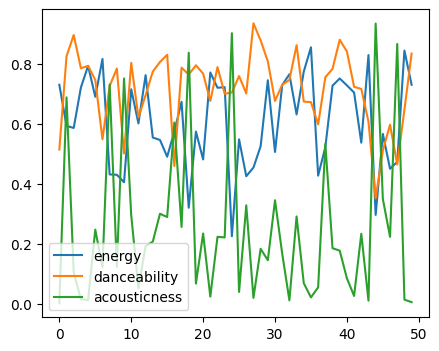

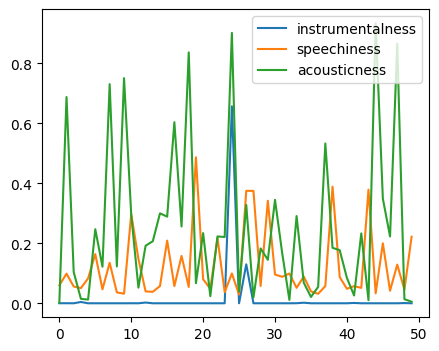

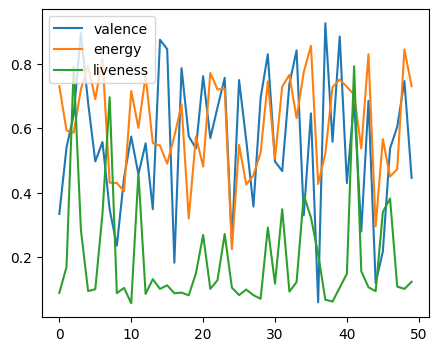

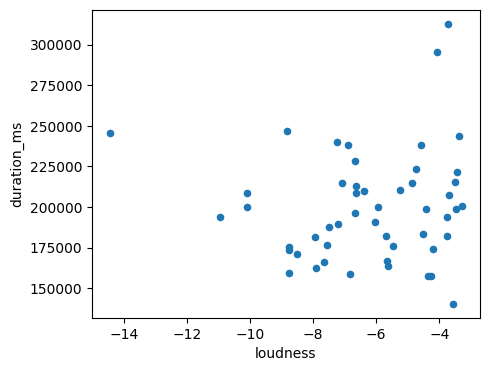

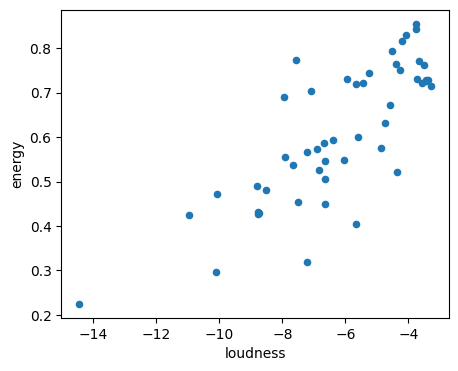

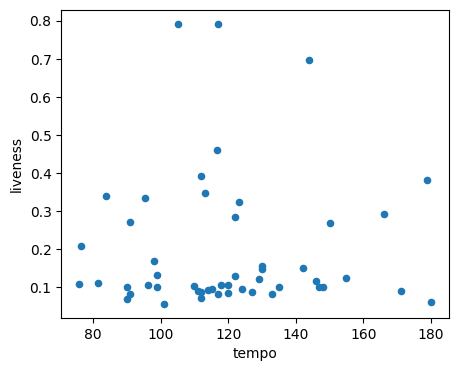

In [51]:
# Plot some of the features to see how they look compared each other and
# get a better picture:
data.plot(y = ['energy','danceability', 'acousticness'], figsize = (5, 4))
data.plot(y = ['instrumentalness','speechiness', 'acousticness'], figsize = (5, 4))
data.plot(y = ['valence','energy', 'liveness'], figsize = (5, 4))
data.plot(x = 'loudness', y = 'duration_ms', kind='scatter', figsize = (5, 4))
data.plot(x = 'loudness', y = 'energy', kind='scatter', figsize = (5, 4))
data.plot(x = 'tempo', y = 'liveness', kind='scatter', figsize = (5, 4))

There seems to be some correlation between features. Monotonic associations between variables are going to be assumed. Monotonicity is "less restrictive" than that of a linear relationship. Therefore, Spearman's correlation was used.

In [52]:
# Calculation of Spearman's correlation between numeric features:
correlation = data.loc[:, 'energy':'duration_ms'].corr(method = 'spearman').stack()

# Removing of unnesessary "self-correlation" values:
correlation = correlation[correlation.index.get_level_values(0) != correlation.index.get_level_values(1)]
correlation.unstack()

,energy,danceability,key,loudness,acousticness,speechiness,instrumentalness,liveness,valence,tempo,duration_ms
energy,NaN,0.052969,0.067692,0.752383,-0.655446,0.084088,0.183205,0.129046,0.299116,0.071886,0.079762
danceability,0.052969,NaN,0.239185,0.117605,-0.132543,0.297988,0.024121,-0.129914,0.426510,0.236170,0.001921
key,0.067692,0.239185,NaN,-0.034895,-0.091704,0.016483,-0.028765,0.146500,0.141376,0.091751,0.014286
loudness,0.752383,0.117605,-0.034895,NaN,-0.402123,-0.040290,0.081553,-0.125729,0.335871,0.090228,0.125666
acousticness,-0.655446,-0.132543,-0.091704,-0.402123,NaN,0.029390,-0.051258,-0.123523,-0.125366,-0.246777,0.044659
speechiness,0.084088,0.297988,0.016483,-0.040290,0.029390,NaN,0.052461,-0.050189,0.079721,0.131339,0.324001
instrumentalness,0.183205,0.024121,-0.028765,0.081553,-0.051258,0.052461,NaN,-0.051766,0.094416,0.015707,0.203296
liveness,0.129046,-0.129914,0.146500,-0.125729,-0.123523,-0.050189,-0.051766,NaN,-0.102060,0.018634,0.019354
valence,0.299116,0.426510,0.141376,0.335871,-0.125366,0.079721,0.094416,-0.102060,NaN,-0.013254,-0.065791
tempo,0.071886,0.236170,0.091751,0.090228,-0.246777,0.131339,0.015707,0.018634,-0.013254,NaN,0.103673


In [53]:
# correlation above 0.5 is considered strong:
strongly_correlated = correlation[(correlation > 0.5)[correlation > 0.5].index]
strongly_correlated

energy    loudness    0.752383
loudness  energy      0.752383
dtype: float64

Only energy and loudness are strongly correlated.

In [54]:
# Which features are strongly negatively corralated?

# Correlation above 0.5 is considered strong:
strongly_negatively_correlated = correlation[(correlation < -0.5)[correlation < -0.5].index]
strongly_negatively_correlated

energy        acousticness   -0.655446
acousticness  energy         -0.655446
dtype: float64

Only energy and acousticness are strongly negatively correlated.

In [55]:
# Which features are not correlated?

# statisticaly only if correlation is 0 we can consider that there is no 
# correlation
no_correlation =  correlation[(correlation == 0)[correlation == 0].index]
no_correlation

Series([], dtype: float64)

Therefore all values are at least weakly correlated. However, we can check values which values are around 0.

In [56]:
# Values that are very weakly correlated, that is around 0 
# (some arbitrary value was chose like: -0.05 < 0 < 0.05):
correlation_around_0 = correlation[correlation.between(-0.05, 0.05)[correlation.between(-0.05, 0.05)].index]
correlation_around_0

danceability      instrumentalness    0.024121
                  duration_ms         0.001921
key               loudness           -0.034895
                  speechiness         0.016483
                  instrumentalness   -0.028765
                  duration_ms         0.014286
loudness          key                -0.034895
                  speechiness        -0.040290
acousticness      speechiness         0.029390
                  duration_ms         0.044659
speechiness       key                 0.016483
                  loudness           -0.040290
                  acousticness        0.029390
instrumentalness  danceability        0.024121
                  key                -0.028765
                  tempo               0.015707
liveness          tempo               0.018634
                  duration_ms         0.019354
valence           tempo              -0.013254
tempo             instrumentalness    0.015707
                  liveness            0.018634
             

There are a lot of features which are very weakly correlated. Duration and key features seems to be "least correlated" with rest of the features as both have 4 features they weakly correlated with. However, energy feature is missing from this list. It seems to be weakly or moderatelly correlated with all of the features.

## Pop, Hip-Hop/Rap, Dance/Electronic, and Alternative/Indie genres comparisons

First lets select Pop, Hip-Hop/Rap, Dance/Electronic, and Alternative/Indie genres songs from dataset and separate them according to genres. 

In [57]:
# Pop songs:
pop_songs = data.loc[genres.loc[genres['pop'] == 1].index]

# Hip-hop/Rap songs:
hiphop_rap_songs = data.loc[data.genre.str.contains('Hip-Hop/Rap')]

# Dance/Electronic songs:
dance_electronic_songs = data.loc[data.genre.str.contains('Dance/Electronic')]

# Alternative/Indie songs:
alternative_indie_songs = data.loc[data.genre.str.contains('Alternative/Indie')]

In [58]:
# How does danceability score compare between Pop, Hip-Hop/Rap, Dance/Electronic, and Alternative/Indie genres?
print(f'''
      Pop songs have mean danceability of {round(pop_songs.danceability.mean(),3)}\u00B1{round(pop_songs.danceability.std(),3)}. 
      Hip-hop/Rap songs have mean danceability of {round(hiphop_rap_songs.danceability.mean(),3)}\u00B1{round(hiphop_rap_songs.danceability.std(),3)}.
      Dance/Electronic songs have mean danceability of {round(dance_electronic_songs.danceability.mean(),3)}\u00B1{round(dance_electronic_songs.danceability.std(),3)}.
      Alternative/Indie songs have mean danceability of {round(alternative_indie_songs.danceability.mean(),3)}\u00B1{round(alternative_indie_songs.danceability.std(),3)}.
      ''')


      Pop songs have mean danceability of 0.679±0.106. 
      Hip-hop/Rap songs have mean danceability of 0.766±0.085.
      Dance/Electronic songs have mean danceability of 0.755±0.095.
      Alternative/Indie songs have mean danceability of 0.662±0.211.
      


Alternative/Indie songs have lowest mean danceability and highest variation in it (0.662±0.211). Pop music has slightly higher danceability (0.679±0.106). Hip-hop/Rap songs have highest mean danceability out of these genres (0.766±0.085). Dance/Electronic has slightly lower mean danciability score (0.755±0.095).

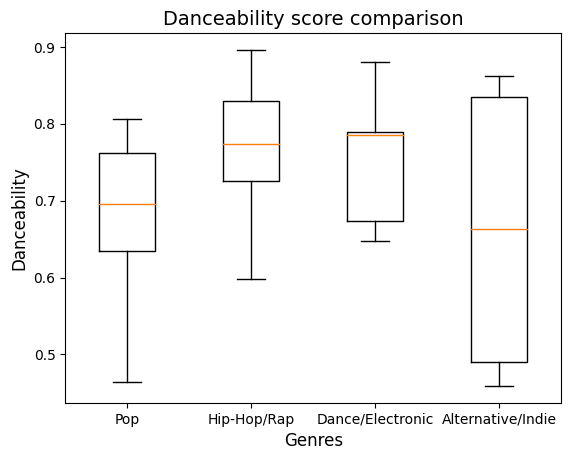

In [59]:
plt.boxplot(
           [pop_songs.danceability, hiphop_rap_songs.danceability, 
            dance_electronic_songs.danceability, 
            alternative_indie_songs.danceability],
            labels = ['Pop', 'Hip-Hop/Rap', 'Dance/Electronic',
                     'Alternative/Indie'],
            )
plt.title('Danceability score comparison', size = 14)
plt.ylabel('Danceability', size = 12)
plt.xlabel('Genres', size = 12)
plt.show()

In [60]:
# How does the loudness score compare between Pop, Hip-Hop/Rap, Dance/Electronic, and Alternative/Indie genres?

print(f'''
      Pop songs have mean loudness of {round(pop_songs.loudness.mean(),3)}\u00B1{round(pop_songs.loudness.std(),3)} dB. 
      Hip-hop/Rap songs have mean loudness of {round(hiphop_rap_songs.loudness.mean(),3)}\u00B1{round(hiphop_rap_songs.loudness.std(),3)} dB.
      Dance/Electronic songs have mean loudness of {round(dance_electronic_songs.loudness.mean(),3)}\u00B1{round(dance_electronic_songs.loudness.std(),3)} dB.
      Alternative/Indie songs have mean loudness of {round(alternative_indie_songs.loudness.mean(),3)}\u00B1{round(alternative_indie_songs.loudness.std(),3)} dB.
      ''')


      Pop songs have mean loudness of -6.263±3.004 dB. 
      Hip-hop/Rap songs have mean loudness of -6.918±1.892 dB.
      Dance/Electronic songs have mean loudness of -5.338±1.479 dB.
      Alternative/Indie songs have mean loudness of -5.421±0.775 dB.
      


Hip-Hop/Rap songs has lowest loudness score (-6.918±1.892 dB). Pop songs have highest variability in loudness score (-6.263±3.004 dB). Dance/Electronic songs have highest loudness score (-5.338±1.479 dB). Alternative/Indie songs have very little variability in loudness between them (-5.421±0.775 dB).

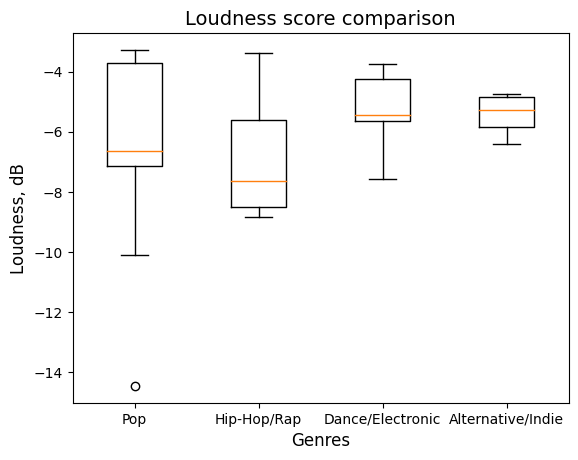

In [61]:
plt.boxplot(
           [pop_songs.loudness, hiphop_rap_songs.loudness, 
            dance_electronic_songs.loudness, 
            alternative_indie_songs.loudness],
            labels = ['Pop', 'Hip-Hop/Rap', 'Dance/Electronic',
                     'Alternative/Indie'],
            )
plt.title('Loudness score comparison', size = 14)
plt.ylabel('Loudness, dB', size = 12)
plt.xlabel('Genres', size = 12)
plt.show()

In [62]:
# How does the acousticness score compare between Pop, Hip-Hop/Rap, Dance/Electronic, and Alternative/Indie genres?

print(f'''
      Pop songs have mean acousticness of {round(pop_songs.acousticness.mean(),3)}\u00B1{round(pop_songs.acousticness.std(),3)}. 
      Hip-hop/Rap songs have mean acousticness of {round(hiphop_rap_songs.acousticness.mean(),3)}\u00B1{round(hiphop_rap_songs.acousticness.std(),3)}.
      Dance/Electronic songs have mean acousticness of {round(dance_electronic_songs.acousticness.mean(),3)}\u00B1{round(dance_electronic_songs.acousticness.std(),3)}.
      Alternative/Indie songs have mean acousticness of {round(alternative_indie_songs.acousticness.mean(),3)}\u00B1{round(alternative_indie_songs.acousticness.std(),3)}.
      ''')


      Pop songs have mean acousticness of 0.315±0.308. 
      Hip-hop/Rap songs have mean acousticness of 0.189±0.186.
      Dance/Electronic songs have mean acousticness of 0.099±0.096.
      Alternative/Indie songs have mean acousticness of 0.584±0.204.
      


Dance/Electronic music has lowest acousticness score (0.099±0.096). Alternative/Indie music has much higher mean acousticness (0.584±0.204) score compared to rest of genres. There are some outlier values with every high acousticness in Pop and Hip-Hop/Rap songs, but overall their mean acousticness is low (Pop – 0.315±0.308; Hip-Hop/Rap – 0.189±0.186).

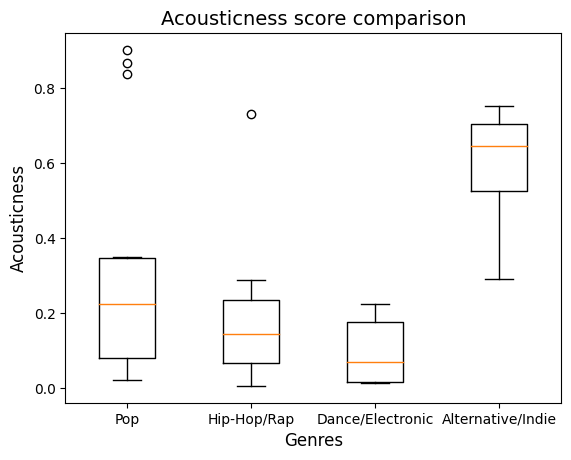

In [63]:
plt.boxplot(
           [pop_songs.acousticness, hiphop_rap_songs.acousticness, 
            dance_electronic_songs.acousticness, 
            alternative_indie_songs.acousticness],
            labels = ['Pop', 'Hip-Hop/Rap', 'Dance/Electronic',
                     'Alternative/Indie'],
            )
plt.title('Acousticness score comparison', size = 14)
plt.ylabel('Acousticness', size = 12)
plt.xlabel('Genres', size = 12)
plt.show()

### Summary

As expected there are 50 songs in the top 50 song list of 2020. The dataset has 16 different features. Data was checked for missing and duplicated values. Also the outlier values were checked. There was 50% of songs with outlier features, however they were not removed from data analysis, as the data set is small and there are strict rules for creating music. There are 40 different artists in the list of whose 7 appeared more than once in list. Top 50 songs features 45 different albums, of which 4 appeared more than once. The most popular song was Blinding lights by The Weeknd. 

Overall, songs with higher loudness score seems to be more popular as there are more songs with higher loudness score (19 songs with loudness score higher than -5 dB), than with lower loudness score in the top 50 (9 songs with loudness lower than -8 dB). Songs with high danceability are popular as well: 32 songs with danceability higher than 0.7, compared to only one which has low danceability (less than 0.4).

Pop and Hip-Hop are most popular genres in the top 50, both appearing 15 times in the list. However, pop is most popular genre with all of its subgenres added up (22 songs). Hip-Hop is the second most popular genre (16 songs). Some of the genres appeared only once in the top 50 list (without counting pop/hip-hop subgenres: disco, nu-disco, soft rock, trap, experimental, reggaeton). Some of the songs had few genres. Genres were separated and in total there were 22 different genres or 15 genres if we consider pop and hip-hop sub-genres not a different genre from pop/hip-hop. 

For correlation analysis, monotonic associations between variables were assumed and Spearman's correlation was used. Monotonicity is "less restrictive" than that of a linear relationship. Energy and loudness are strongly correlated (0.75) and energy and acousticness are strongly negatively correlated (-0.66). There were no values which were not at least weakly correlated (since there were no correlations which were equal to 0). There were quite few features which were very weakly correlated with each other (correlation between -0,05 and 0,05, for example danceability and instrumentalness, duration and danceability, valence and tempo, liveness and tempo), however energy feature was missing from that list. As it stands, energy feature seems to be weakly or moderatelly correlated with all of the features.

For Pop, Hip-Hop/Rap, Dance/Electronic, and Alternative/Indie genres danceability, loudness and acousticness were compared. Alternative/Indie songs have lowest mean danceability and highest variation in it (0.662±0.211). However, they have very little variability in loudness between them (-5.421±0.775 dB). They also have much higher mean acousticness (0.584±0.204) score compared to rest of genres. Dance/Electronic songs have highest loudness score (-5.338±1.479 dB) and lowest acousticness score (0.099±0.096). Pop songs have highest variability in loudness score (-6.263±3.004 dB). Hip-hop/Rap songs have highest mean danceability out of these genres (0.766±0.085) and lowest loudness score (-6.918±1.892 dB). There are some outlier values with every high acousticness in Pop and Hip-Hop/Rap songs, but overall their mean acousticness is low (Pop – 0.315±0.308; Hip-Hop/Rap – 0.189±0.186).

### Suggestions what could be improved

More investigation regarding outliers. Perhaps they are not outliers at all, but are due to differences in genres. These outlier features might be also due to style differences of different artists. Investigate more songs from these genres. However, if outlier song is in top list, it might be good to understand what makes it popular.

Comparisons between songs, if top 50 list has more danceable and louder songs compared to another list of songs, for example top 1000.

Investigate duration preferences. How does length of songs compare to not so popular songs.

Are there any genres which are unusual to this top 50 list? Compare it to other year top 50 lists.

Sometimes artists release stand alone songs without any albums. Investigate if there are any in the top 50 list, and how many if there are.

It would be nice to know how many times the songs were listened to. Also, investigating, for example, how many minutes each song was listened to might give clearer comparison if there is a huge difference between lengths of songs. Perhaps, there are artists which has more than one song in the top 50, and total listening time for their songs is higher, than other artists who is higher, but has only one song.

Also are there many unique individuals who are listening to a song? Perhaps, it is few individuals who listen to the song over and over again.